# Análisis Descriptivo para la Estimación de la LGD (Loss Given Default)
## Caracterización de Créditos Incumplidos en Lending Club

Este notebook desarrolla el **Plan de Análisis Descriptivo** para caracterizar la severidad de la pérdida dado el incumplimiento (**LGD proxy**), evaluando la calidad y consistencia contable de las variables monetarias de Lending Club y sentando las bases estadísticas para la etapa de modelado por regresión.

### Configuración del Entorno y Librerías

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo de visualización elegante y legible
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

# Formato numérico de pandas
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

base_dir = Path.cwd()
csv_path = base_dir / "loan" / "loan.csv"
if not csv_path.exists():
    csv_path = base_dir / "loan.csv"

print(f"Ruta del dataset: {csv_path}")

Ruta del dataset: c:\Users\ADMON\Documents\Universidad\Redes Neuronales\Trabajos\trabajo_2\loan\loan.csv


--- 
## Etapa 1. Exploración y Calidad de Datos

En esta etapa se cargan las variables financieras prioritarias del plan:
- **`loan_status`**: Estado administrativo del crédito.
- **`funded_amnt`**: Monto originalmente financiado (denominador de la LGD).
- **`total_rec_prncp`**: Capital amortizado efectivamente a la fecha.
- **`recoveries`**: Recuperaciones reportadas tras la declaración de castigo (*charge-off*).
- **`collection_recovery_fee`**: Costos de recuperación judicial/agencia.
- **`out_prncp`**: Representa el saldo del capital pendiente pago de un credito, en la fecha que se registraron los datos .
- *(Adicionales para controles contables y cruce de riesgo)*: `total_pymnt`, `grade`, `term`.

In [2]:
cols_analisis = [
    'loan_status', 'funded_amnt', 'total_rec_prncp',
    'recoveries', 'collection_recovery_fee', 'out_prncp',
    'total_pymnt', 'grade', 'term'
]

print("Cargando dataset...")
df_raw = pd.read_csv(csv_path, usecols=cols_analisis, low_memory=False)
print(f"Dimensiones totales: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas")

Cargando dataset...
Dimensiones totales: 887,379 filas × 9 columnas


In [3]:
# Tabla de Calidad de Datos
calidad_df = pd.DataFrame({
    'Tipo de Dato': df_raw.dtypes,
    'Valores Nulos': df_raw.isnull().sum(),
    '% Nulos': (df_raw.isnull().sum() / len(df_raw)) * 100,
    'Valores Únicos': df_raw.nunique(),
    'Ceros Registrados': (df_raw == 0).sum(),
    '% Ceros': ((df_raw == 0).sum() / len(df_raw)) * 100
})

print("--- TABLA DE CALIDAD DE DATOS (DATA QUALITY) ---")
display(calidad_df)

--- TABLA DE CALIDAD DE DATOS (DATA QUALITY) ---


,Tipo de Dato,Valores Nulos,% Nulos,Valores Únicos,Ceros Registrados,% Ceros
funded_amnt,float64,0,0.00,1372,0,0.00
term,object,0,0.00,2,0,0.00
grade,object,0,0.00,7,0,0.00
loan_status,object,0,0.00,10,0,0.00
out_prncp,float64,0,0.00,248332,255798,28.83
total_pymnt,float64,0,0.00,506726,17759,2.00
total_rec_prncp,float64,0,0.00,260227,18145,2.04
recoveries,float64,0,0.00,23055,862702,97.22
collection_recovery_fee,float64,0,0.00,20708,863872,97.35


In [4]:
# Detección de inconsistencias contables iniciales
funded_le_0 = (df_raw['funded_amnt'] <= 0).sum()
neg_prncp = (df_raw['total_rec_prncp'] < 0).sum()
neg_recov = (df_raw['recoveries'] < 0).sum()
prncp_gt_funded = (df_raw['total_rec_prncp'] > df_raw['funded_amnt'] + 1.0).sum()

print("--- VERIFICACIÓN DE REGLAS DE CONSISTENCIA BÁSICAS ---")
print(f"Créditos con funded_amnt <= 0: {funded_le_0}")
print(f"Créditos con total_rec_prncp negativo: {neg_prncp}")
print(f"Créditos con recoveries negativas: {neg_recov}")
print(f"Créditos con total_rec_prncp > funded_amnt: {prncp_gt_funded}")

--- VERIFICACIÓN DE REGLAS DE CONSISTENCIA BÁSICAS ---
Créditos con funded_amnt <= 0: 0
Créditos con total_rec_prncp negativo: 0
Créditos con recoveries negativas: 0
Créditos con total_rec_prncp > funded_amnt: 1


--- 
## Etapa 2. Descripción del Estado Crediticio y Filtrado Analítico

Se exploran las categorías de `loan_status` y se selecciona la muestra de análisis para LGD:
- **Muestra de incumplimiento:** `Charged Off` y `Default`.

--- DISTRIBUCIÓN GLOBAL DE ESTADOS DE CRÉDITO ---


,Frecuencia,Porcentaje (%)
loan_status,,
Current,601779,67.82
Fully Paid,207723,23.41
Charged Off,45248,5.10
Late (31-120 days),11591,1.31
Issued,8460,0.95
In Grace Period,6253,0.70
Late (16-30 days),2357,0.27
Does not meet the credit policy. Status:Fully Paid,1988,0.22
Default,1219,0.14


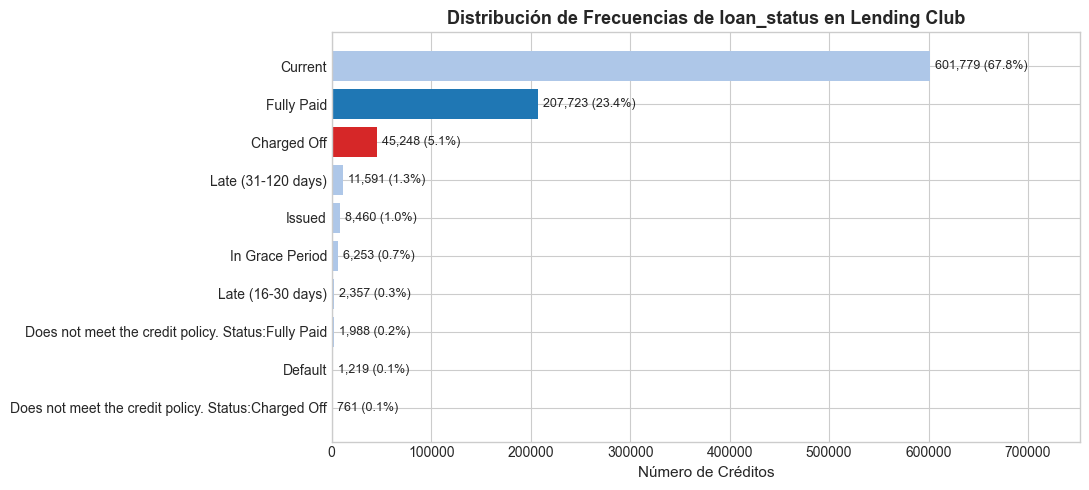

In [5]:
# Distribución de frecuencias de loan_status
status_counts = df_raw['loan_status'].value_counts(dropna=False)
status_pcts = df_raw['loan_status'].value_counts(normalize=True, dropna=False) * 100
status_table = pd.DataFrame({'Frecuencia': status_counts, 'Porcentaje (%)': status_pcts})

print("--- DISTRIBUCIÓN GLOBAL DE ESTADOS DE CRÉDITO ---")
display(status_table)

# Gráfico de frecuencias
plt.figure(figsize=(11, 5))
colors = ['#1f77b4' if s == 'Fully Paid' else ('#d62728' if s in ['Charged Off', 'Default'] else '#aec7e8') for s in status_counts.index]
bars = plt.barh(status_counts.index, status_counts.values, color=colors)
plt.title('Distribución de Frecuencias de loan_status en Lending Club', fontsize=13, weight='bold')
plt.xlabel('Número de Créditos')
for bar in bars:
    w = bar.get_width()
    plt.text(w + 5000, bar.get_y() + bar.get_height()/2, f'{w:,} ({w/len(df_raw)*100:.1f}%)', va='center', fontsize=9)
plt.gca().invert_yaxis()
plt.xlim(0, status_counts.max() * 1.25)
plt.tight_layout()
plt.show()

In [6]:
# Filtrado de la población objetivo para el análisis de severidad (LGD)
default_labels = ['Charged Off', 'Default']
df_defaults = df_raw[df_raw['loan_status'].isin(default_labels)].copy()

print(f"Total créditos antes del filtrado: {len(df_raw):,}")
print(f"Total créditos en muestra de incumplimiento (Charged Off + Default): {len(df_defaults):,}")
print(f"Proporción sobre la cartera total: {(len(df_defaults) / len(df_raw))*100:.2f}%")
print("\nDesglose de la muestra analítica:")
print(df_defaults['loan_status'].value_counts())

Total créditos antes del filtrado: 887,379
Total créditos en muestra de incumplimiento (Charged Off + Default): 46,467
Proporción sobre la cartera total: 5.24%

Desglose de la muestra analítica:
loan_status
Charged Off    45248
Default         1219
Name: count, dtype: int64


--- 
## Etapa 3. Análisis Univariado de Variables Monetarias (Población en Incumplimiento)

Se calculan estadísticas de localización, dispersión y cuantiles (incluyendo p5 y p95) para las 5 variables monetarias del plan en la muestra de incumplimiento.

In [7]:
monetary_cols = ['funded_amnt', 'total_rec_prncp', 'recoveries', 'collection_recovery_fee', 'out_prncp']

def resumen_univariado(df, cols):
    resumen = []
    for col in cols:
        s = df[col].dropna()
        resumen.append({
            'Variable': col,
            'Conteo': len(s),
            'Media': s.mean(),
            'Std': s.std(),
            'Min': s.min(),
            'p5': s.quantile(0.05),
            'Q1 (25%)': s.quantile(0.25),
            'Mediana': s.median(),
            'Q3 (75%)': s.quantile(0.75),
            'p95': s.quantile(0.95),
            'Max': s.max(),
            '% Ceros': (s == 0).mean() * 100
        })
    return pd.DataFrame(resumen).set_index('Variable')

stats_monetarias = resumen_univariado(df_defaults, monetary_cols)
print("--- ESTADÍSTICAS UNIVARIADAS (CRÉDITOS EN INCUMPLIMIENTO) ---")
display(stats_monetarias)

--- ESTADÍSTICAS UNIVARIADAS (CRÉDITOS EN INCUMPLIMIENTO) ---


,Conteo,Media,Std,Min,p5,Q1 (25%),Mediana,Q3 (75%),p95,Max,% Ceros
Variable,,,,,,,,,,,
funded_amnt,46467,"14,528.67","8,366.12",900.00,"3,500.00","8,000.00","12,600.00","20,000.00","31,300.00","35,000.00",0.00
total_rec_prncp,46467,"3,333.52","3,292.83",0.00,281.38,"1,105.88","2,324.11","4,455.39","9,741.65","34,483.27",1.23
recoveries,46467,867.44,"1,559.67",0.00,0.00,0.00,16.25,"1,214.16","3,797.43","33,520.27",47.95
collection_recovery_fee,46467,91.21,253.07,0.00,0.00,0.00,0.00,24.92,581.83,"7,002.19",50.43
out_prncp,46467,304.18,"2,219.35",0.00,0.00,0.00,0.00,0.00,0.00,"35,000.00",97.38


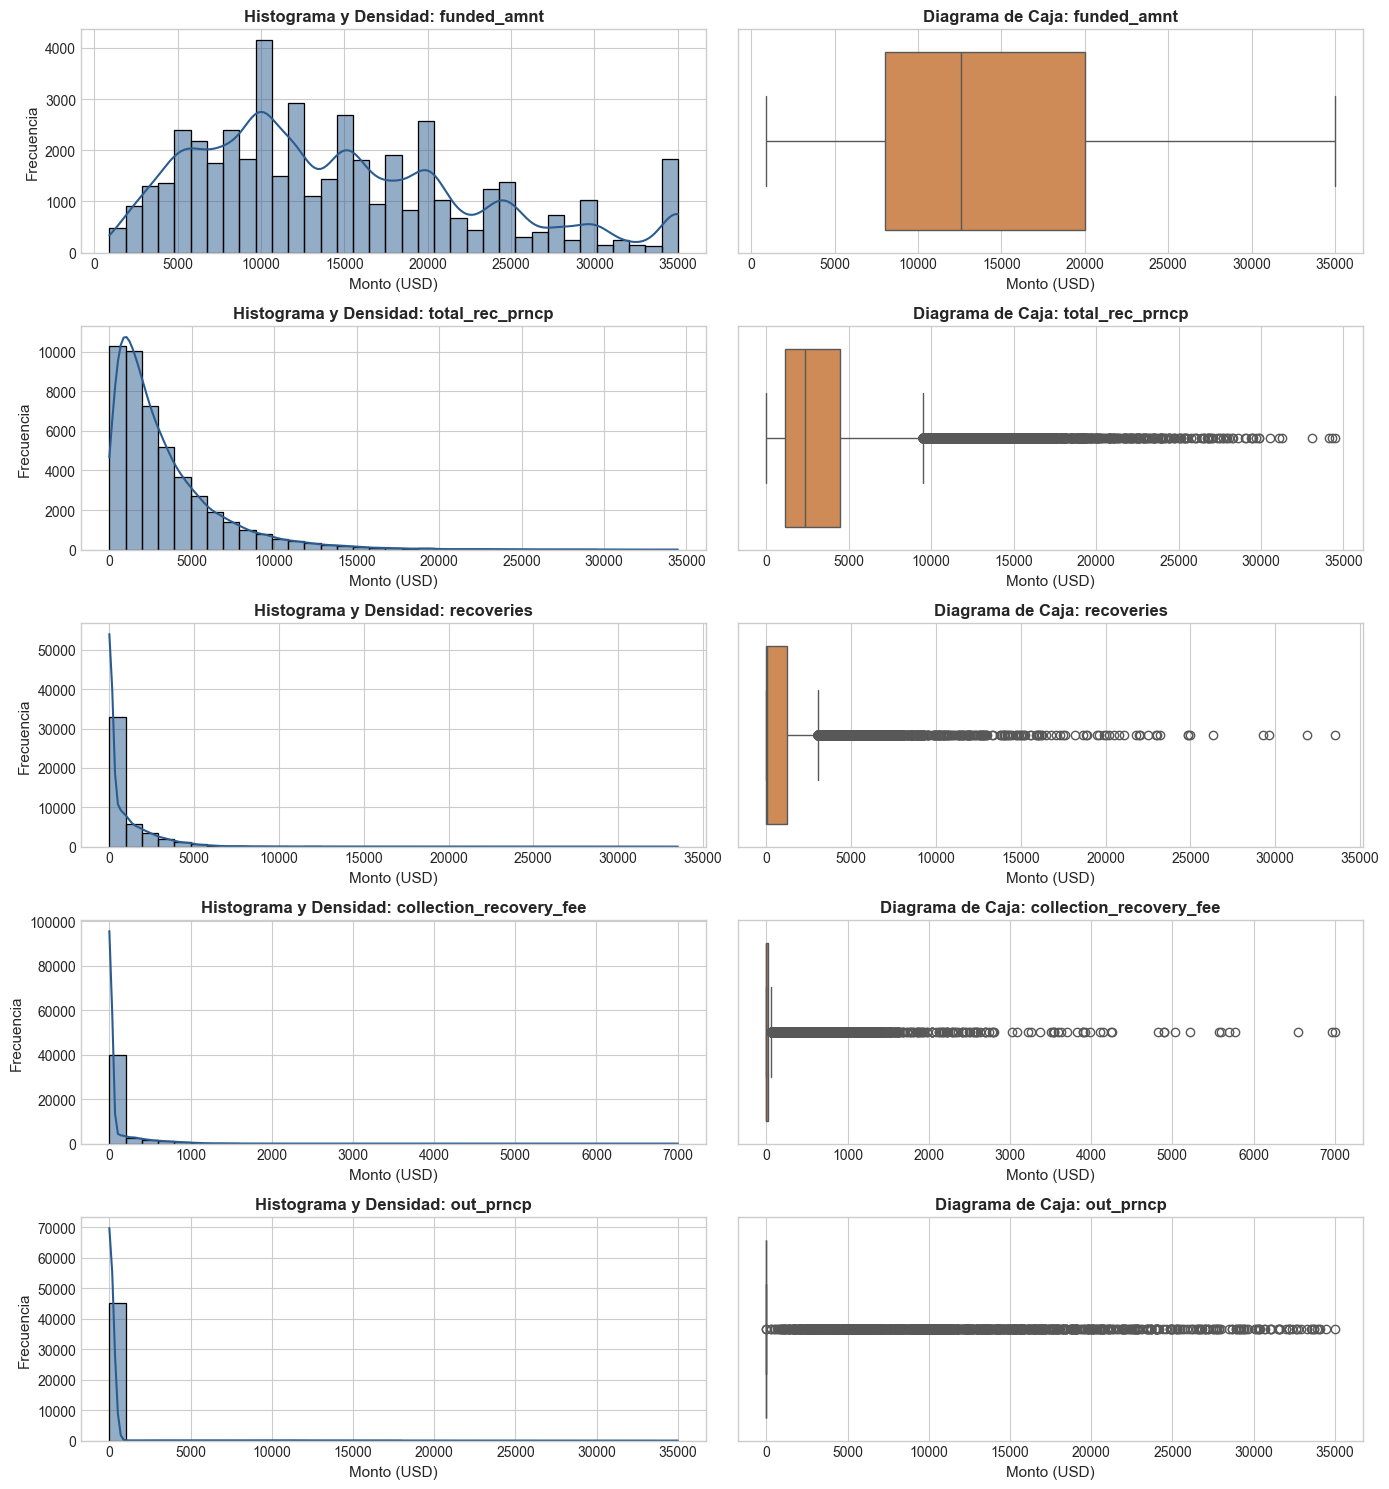

In [8]:
# Visualización: Histogramas y Diagramas de Caja
fig, axes = plt.subplots(len(monetary_cols), 2, figsize=(14, 15))

for i, col in enumerate(monetary_cols):
    # Histograma con KDE
    sns.histplot(df_defaults[col], bins=35, kde=True, ax=axes[i, 0], color='#2b5c8f')
    axes[i, 0].set_title(f'Histograma y Densidad: {col}', fontweight='bold')
    axes[i, 0].set_xlabel('Monto (USD)')
    axes[i, 0].set_ylabel('Frecuencia')
    
    # Diagrama de Caja
    sns.boxplot(x=df_defaults[col], ax=axes[i, 1], color='#e28743')
    axes[i, 1].set_title(f'Diagrama de Caja: {col}', fontweight='bold')
    axes[i, 1].set_xlabel('Monto (USD)')

plt.tight_layout()
plt.show()

--- 
## Etapa 4. Comparación por Estado de Incumplimiento: `Charged Off` vs `Default`

Contrastamos los créditos formalmente castigados (`Charged Off`) frente a los que se encuentran en atraso superior a 120 días (`Default`).

In [9]:
# Tabla comparativa de estadísticas por estado
comp_rows = []
for status in ['Charged Off', 'Default']:
    sub = df_defaults[df_defaults['loan_status'] == status]
    for col in monetary_cols:
        comp_rows.append({
            'Estado': status,
            'Variable': col,
            'Conteo': len(sub),
            'Media': sub[col].mean(),
            'Mediana': sub[col].median(),
            'Desv. Est.': sub[col].std(),
            '% Ceros': (sub[col] == 0).mean() * 100
        })

tabla_comp = pd.DataFrame(comp_rows).set_index(['Variable', 'Estado'])
print("--- COMPARACIÓN DE VARIABLES MONETARIAS ENTRE CHARGED OFF Y DEFAULT ---")
display(tabla_comp)

--- COMPARACIÓN DE VARIABLES MONETARIAS ENTRE CHARGED OFF Y DEFAULT ---


,,Conteo,Media,Mediana,Desv. Est.,% Ceros
Variable,Estado,,,,,
funded_amnt,Charged Off,45248,"14,510.75","12,600.00","8,366.82",0.00
total_rec_prncp,Charged Off,45248,"3,326.37","2,319.40","3,282.27",1.24
recoveries,Charged Off,45248,890.81,35.06,"1,573.94",46.55
collection_recovery_fee,Charged Off,45248,93.66,1.07,256.00,49.09
out_prncp,Charged Off,45248,0.00,0.00,0.00,100.00
funded_amnt,Default,1219,"15,193.85","13,675.00","8,315.96",0.00
total_rec_prncp,Default,1219,"3,598.86","2,418.93","3,654.98",0.74
recoveries,Default,1219,0.00,0.00,0.00,100.00
collection_recovery_fee,Default,1219,0.00,0.00,0.00,100.00


C:\Users\ADMON\AppData\Local\Temp\ipykernel_36848\1259739159.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_defaults, x='loan_status', y='funded_amnt', palette=['#c0392b', '#2980b9'], ax=axes[0])
C:\Users\ADMON\AppData\Local\Temp\ipykernel_36848\1259739159.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_defaults, x='loan_status', y='total_rec_prncp', palette=['#c0392b', '#2980b9'], ax=axes[1])
C:\Users\ADMON\AppData\Local\Temp\ipykernel_36848\1259739159.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_def

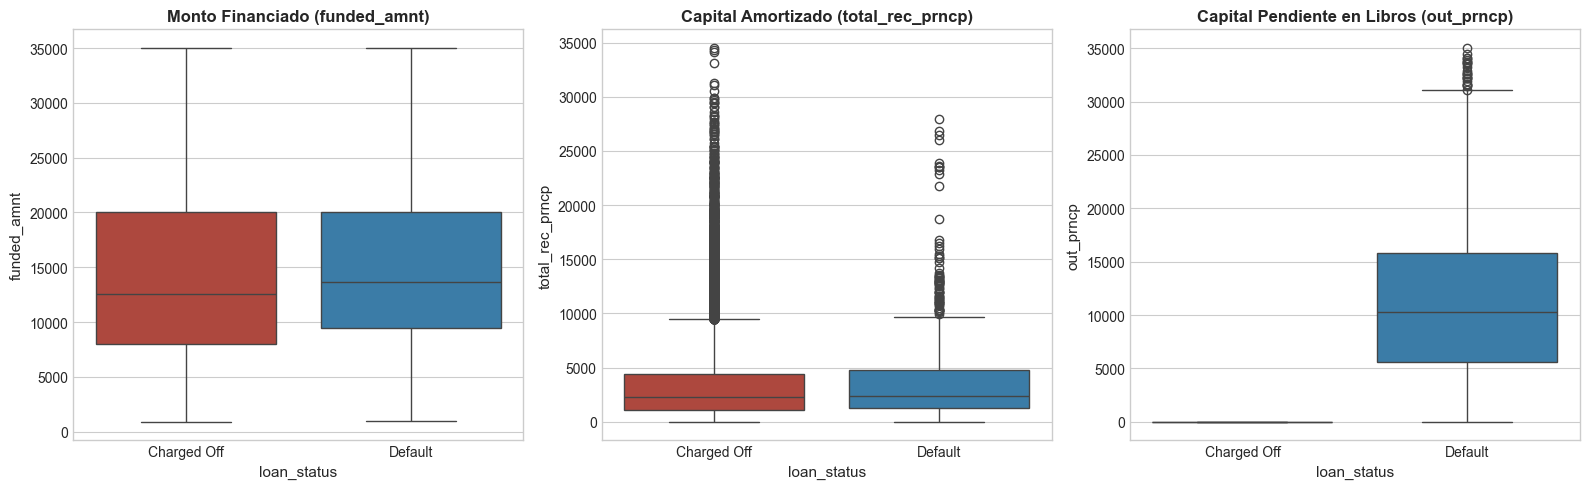

HALLAZGO CONTABLE:
- En 'Charged Off': out_prncp == 0 en el 100.00% de los casos (castigo contable del balance activo).
- En 'Default': out_prncp > 0 en el 99.92% de los casos, y recoveries == 0 en el 100% (aún no formaliza cobranza post-castigo).


In [10]:
# Comparación gráfica de distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(data=df_defaults, x='loan_status', y='funded_amnt', palette=['#c0392b', '#2980b9'], ax=axes[0])
axes[0].set_title('Monto Financiado (funded_amnt)', fontweight='bold')

sns.boxplot(data=df_defaults, x='loan_status', y='total_rec_prncp', palette=['#c0392b', '#2980b9'], ax=axes[1])
axes[1].set_title('Capital Amortizado (total_rec_prncp)', fontweight='bold')

sns.boxplot(data=df_defaults, x='loan_status', y='out_prncp', palette=['#c0392b', '#2980b9'], ax=axes[2])
axes[2].set_title('Capital Pendiente en Libros (out_prncp)', fontweight='bold')

plt.tight_layout()
plt.show()

# Hallazgo clave documentado:
print("HALLAZGO CONTABLE:")
print(f"- En 'Charged Off': out_prncp == 0 en el {((df_defaults[df_defaults['loan_status'] == 'Charged Off']['out_prncp'] == 0).mean()*100):.2f}% de los casos (castigo contable del balance activo).")
print(f"- En 'Default': out_prncp > 0 en el {((df_defaults[df_defaults['loan_status'] == 'Default']['out_prncp'] > 0).mean()*100):.2f}% de los casos, y recoveries == 0 en el 100% (aún no formaliza cobranza post-castigo).")

--- 
## Etapa 5. Relaciones Bivariadas y Controles de Consistencia Contable

Se exploran las relaciones entre variables monetarias y se verifica experimentalmente la descomposición contable para evitar duplicidad de flujos.

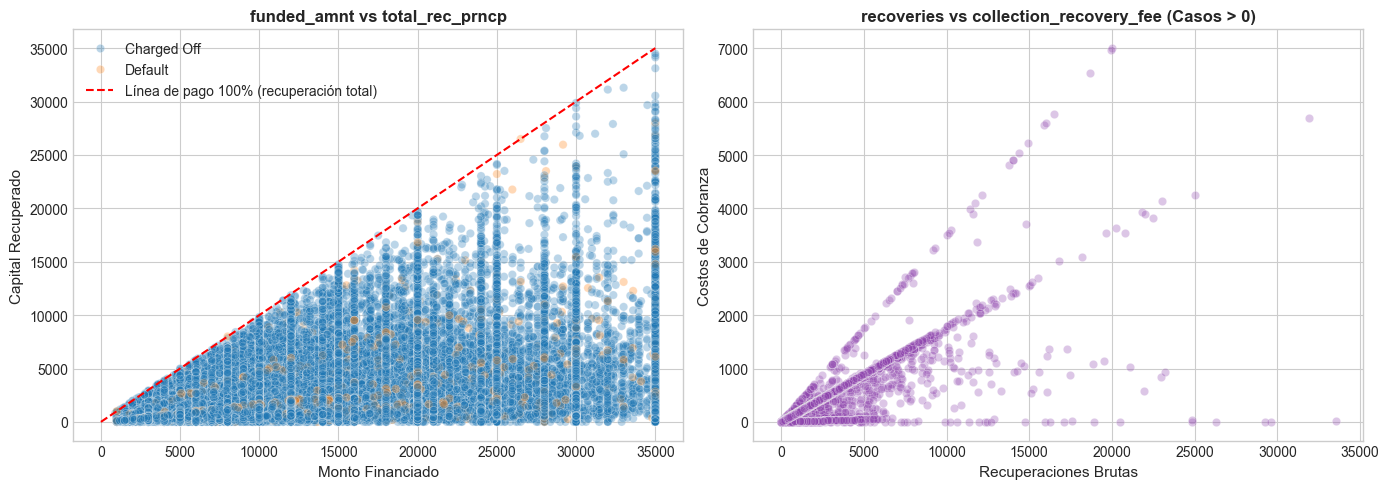

In [11]:
# 1. Diagrama de Dispersión y Correlaciones
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df_defaults, x='funded_amnt', y='total_rec_prncp', hue='loan_status', alpha=0.3, ax=axes[0])
axes[0].plot([0, 35000], [0, 35000], 'r--', label='Línea de pago 100% (recuperación total)')
axes[0].set_title('funded_amnt vs total_rec_prncp', fontweight='bold')
axes[0].set_xlabel('Monto Financiado')
axes[0].set_ylabel('Capital Recuperado')
axes[0].legend()

# Relación recoveries vs collection_recovery_fee
df_recov = df_defaults[df_defaults['recoveries'] > 0]
sns.scatterplot(data=df_recov, x='recoveries', y='collection_recovery_fee', alpha=0.3, color='#8e44ad', ax=axes[1])
axes[1].set_title('recoveries vs collection_recovery_fee (Casos > 0)', fontweight='bold')
axes[1].set_xlabel('Recuperaciones Brutas')
axes[1].set_ylabel('Costos de Cobranza')

plt.tight_layout()
plt.show()

In [12]:
# 2. Verificación Contable de Independencia de Flujos (Aporte Metodológico):
# Comprobamos si 'total_rec_prncp' y 'recoveries' son mutuamente excluyentes dentro de 'total_pymnt'
# En Lending Club: total_pymnt = total_rec_prncp + total_rec_int + total_rec_late_fee + recoveries
diff_check = (df_defaults['total_pymnt'] - (df_defaults['total_rec_prncp'] + df_defaults['recoveries'])).dropna()

print("VERIFICACIÓN DE NO-SUPERPOSICIÓN CONTABLE:")
print(f"- Proporción de créditos donde total_pymnt >= total_rec_prncp + recoveries: {(diff_check >= -0.01).mean()*100:.2f}%")
print("Conclusión: 'recoveries' NO está contenido dentro de 'total_rec_prncp'. Ambas variables representan flujos monetarios distintos y válidos para la recuperación neta.")

VERIFICACIÓN DE NO-SUPERPOSICIÓN CONTABLE:
- Proporción de créditos donde total_pymnt >= total_rec_prncp + recoveries: 100.00%
Conclusión: 'recoveries' NO está contenido dentro de 'total_rec_prncp'. Ambas variables representan flujos monetarios distintos y válidos para la recuperación neta.


--- 
## Etapa 6. Construcción de Indicadores Derivados

Calculamos las métricas fundamentales del plan descriptivo:
- **Capital no recuperado:** $CNR_i = funded\_amnt_i - total\_rec\_prncp_i$
- **Tasa de recuperación del capital original:** $TR_i = \frac{total\_rec\_prncp_i}{funded\_amnt_i}$
- **LGD proxy individual:** $LGD_i^{proxy} = 1 - \frac{total\_rec\_prncp_i}{funded\_amnt_i}$
- **Recuperaciones netas post-castigo:** $RN_i = recoveries_i - collection\_recovery\_fee_i$
- **LGD neta integral (con recuperaciones):** $LGD_i^{neta} = 1 - \frac{total\_rec\_prncp_i + RN_i}{funded\_amnt_i}$
- **LGD proxy agregada ponderada:** $\frac{\sum CNR_i}{\sum funded\_amnt_i}$

In [13]:
# Validar funded_amnt > 0
valid_mask = df_defaults['funded_amnt'] > 0
df_indicadores = df_defaults[valid_mask].copy()

# Indicadores del plan
df_indicadores['CNR'] = df_indicadores['funded_amnt'] - df_indicadores['total_rec_prncp']
df_indicadores['TR'] = df_indicadores['total_rec_prncp'] / df_indicadores['funded_amnt']
df_indicadores['LGD_proxy'] = 1 - df_indicadores['TR']

# Recuperaciones netas
df_indicadores['RN'] = df_indicadores['recoveries'] - df_indicadores['collection_recovery_fee']

# LGD neta integral (incluyendo cobranza post-castigo)
df_indicadores['TR_neta'] = (df_indicadores['total_rec_prncp'] + df_indicadores['RN']) / df_indicadores['funded_amnt']
df_indicadores['LGD_neta'] = 1 - df_indicadores['TR_neta']

# Aplicación de clipping [0, 1] para consistencia económica
df_indicadores['LGD_proxy_clip'] = df_indicadores['LGD_proxy'].clip(0.0, 1.0)
df_indicadores['LGD_neta_clip'] = df_indicadores['LGD_neta'].clip(0.0, 1.0)

print(f"Indicadores calculados exitosamente sobre {len(df_indicadores):,} créditos.")
display(df_indicadores[['funded_amnt', 'total_rec_prncp', 'CNR', 'TR', 'LGD_proxy_clip', 'RN', 'LGD_neta_clip']].head())

Indicadores calculados exitosamente sobre 46,467 créditos.


,funded_amnt,total_rec_prncp,CNR,TR,LGD_proxy_clip,RN,LGD_neta_clip
1,"2,500.00",456.46,"2,043.54",0.18,0.82,115.97,0.77
8,"5,600.00",162.02,"5,437.98",0.03,0.97,186.97,0.94
9,"5,375.00",673.48,"4,701.52",0.13,0.87,266.77,0.83
12,"9,000.00","1,256.14","7,743.86",0.14,0.86,440.14,0.81
14,"10,000.00","5,433.47","4,566.53",0.54,0.46,638.79,0.39


In [14]:
# Métricas Agregadas Ponderadas
total_funded = df_indicadores['funded_amnt'].sum()
total_rec = df_indicadores['total_rec_prncp'].sum()
total_cnr = df_indicadores['CNR'].sum()
total_rn = df_indicadores['RN'].sum()

lgd_agregada_proxy = total_cnr / total_funded
lgd_agregada_neta = (total_funded - total_rec - total_rn) / total_funded

print("="*50)
print("RESUMEN AGREGADO DE CARTERA INCUMPLIDA:")
print(f"- Capital total financiado en incumplimiento: ${total_funded:,.2f}")
print(f"- Capital total amortizado recuperado:       ${total_rec:,.2f}")
print(f"- Capital total no recuperado (CNR):         ${total_cnr:,.2f}")
print(f"- Recuperaciones netas post-castigo:         ${total_rn:,.2f}")
print("-"*50)
print(f"- LGD Agregada Ponderada (solo capital):     {lgd_agregada_proxy*100:.2f}%")
print(f"- LGD Agregada Ponderada (con recuperaciones):{lgd_agregada_neta*100:.2f}%")
print("="*50)

RESUMEN AGREGADO DE CARTERA INCUMPLIDA:
- Capital total financiado en incumplimiento: $675,103,675.00
- Capital total amortizado recuperado:       $154,898,455.61
- Capital total no recuperado (CNR):         $520,205,219.39
- Recuperaciones netas post-castigo:         $36,069,054.75
--------------------------------------------------
- LGD Agregada Ponderada (solo capital):     77.06%
- LGD Agregada Ponderada (con recuperaciones):71.71%


--- 
## Etapa 7. Descripción de la LGD Proxy y Distribución de Severidad

Analizamos la distribución de la LGD, la bimodalidad típica en carteras de crédito y contrastamos promedio simple vs promedio ponderado.

In [15]:
lgd_cols = ['LGD_proxy_clip', 'LGD_neta_clip']
stats_lgd = resumen_univariado(df_indicadores, lgd_cols)
print("--- DISTRIBUCIÓN ESTADÍSTICA DE LGD ---")
display(stats_lgd)

# Comparación simple vs ponderada
comp_medias = pd.DataFrame({
    'Métrica': ['LGD Proxy (Solo Capital)', 'LGD Neta (Con Recuperaciones)'],
    'Promedio Simple': [df_indicadores['LGD_proxy_clip'].mean(), df_indicadores['LGD_neta_clip'].mean()],
    'Promedio Ponderado': [lgd_agregada_proxy, lgd_agregada_neta],
    'Diferencia': [df_indicadores['LGD_proxy_clip'].mean() - lgd_agregada_proxy, df_indicadores['LGD_neta_clip'].mean() - lgd_agregada_neta]
})
print("\n--- COMPARACIÓN PROMEDIO SIMPLE VS PONDERADO ---")
display(comp_medias)

--- DISTRIBUCIÓN ESTADÍSTICA DE LGD ---


,Conteo,Media,Std,Min,p5,Q1 (25%),Mediana,Q3 (75%),p95,Max,% Ceros
Variable,,,,,,,,,,,
LGD_proxy_clip,46467,0.75,0.20,0.00,0.33,0.65,0.81,0.90,0.97,1.00,0.00
LGD_neta_clip,46467,0.70,0.20,0.00,0.29,0.59,0.74,0.85,0.95,1.00,0.09



--- COMPARACIÓN PROMEDIO SIMPLE VS PONDERADO ---


,Métrica,Promedio Simple,Promedio Ponderado,Diferencia
0,LGD Proxy (Solo Capital),0.75,0.77,-0.02
1,LGD Neta (Con Recuperaciones),0.70,0.72,-0.02


C:\Users\ADMON\AppData\Local\Temp\ipykernel_36848\4059684653.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_indicadores, x='loan_status', y='LGD_proxy_clip', palette=['#e74c3c', '#3498db'], ax=axes[1])


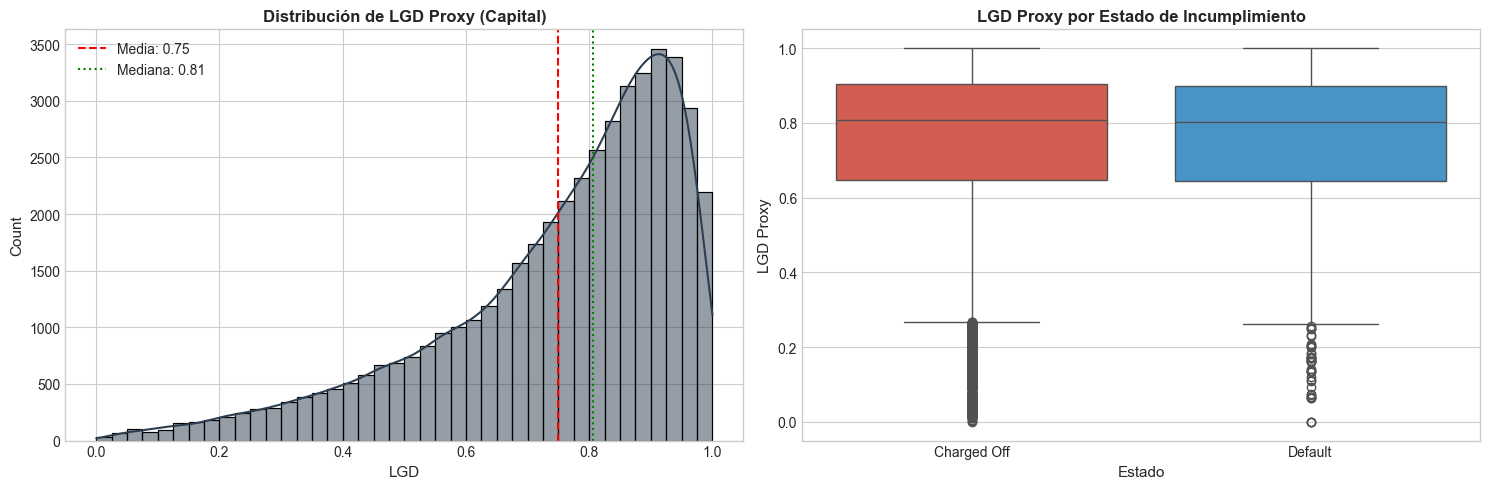

In [16]:
# Visualización de la distribución de LGD (Bimodalidad)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histograma de LGD Proxy
sns.histplot(df_indicadores['LGD_proxy_clip'], bins=40, kde=True, color='#2c3e50', ax=axes[0])
axes[0].axvline(df_indicadores['LGD_proxy_clip'].mean(), color='red', linestyle='--', label=f'Media: {df_indicadores["LGD_proxy_clip"].mean():.2f}')
axes[0].axvline(df_indicadores['LGD_proxy_clip'].median(), color='green', linestyle=':', label=f'Mediana: {df_indicadores["LGD_proxy_clip"].median():.2f}')
axes[0].set_title('Distribución de LGD Proxy (Capital)', fontweight='bold')
axes[0].set_xlabel('LGD')
axes[0].legend()

# Comparación por estado (Charged Off vs Default)
sns.boxplot(data=df_indicadores, x='loan_status', y='LGD_proxy_clip', palette=['#e74c3c', '#3498db'], ax=axes[1])
axes[1].set_title('LGD Proxy por Estado de Incumplimiento', fontweight='bold')
axes[1].set_xlabel('Estado')
axes[1].set_ylabel('LGD Proxy')

plt.tight_layout()
plt.show()

### Aporte Adicional: Cruce de LGD con Variables de Riesgo Ex-Ante

Exploramos cómo varía la severidad de pérdida empírica según el grado de riesgo crediticio asignado al originar (`grade`: de A hasta G) y el plazo del crédito (`term`: 36 vs 60 meses).

C:\Users\ADMON\AppData\Local\Temp\ipykernel_36848\739512489.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_indicadores, x='grade', y='LGD_proxy_clip', order=order_grades, palette='Blues_r', errorbar=None)
C:\Users\ADMON\AppData\Local\Temp\ipykernel_36848\739512489.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_indicadores, x='term', y='LGD_proxy_clip', palette='Set2')


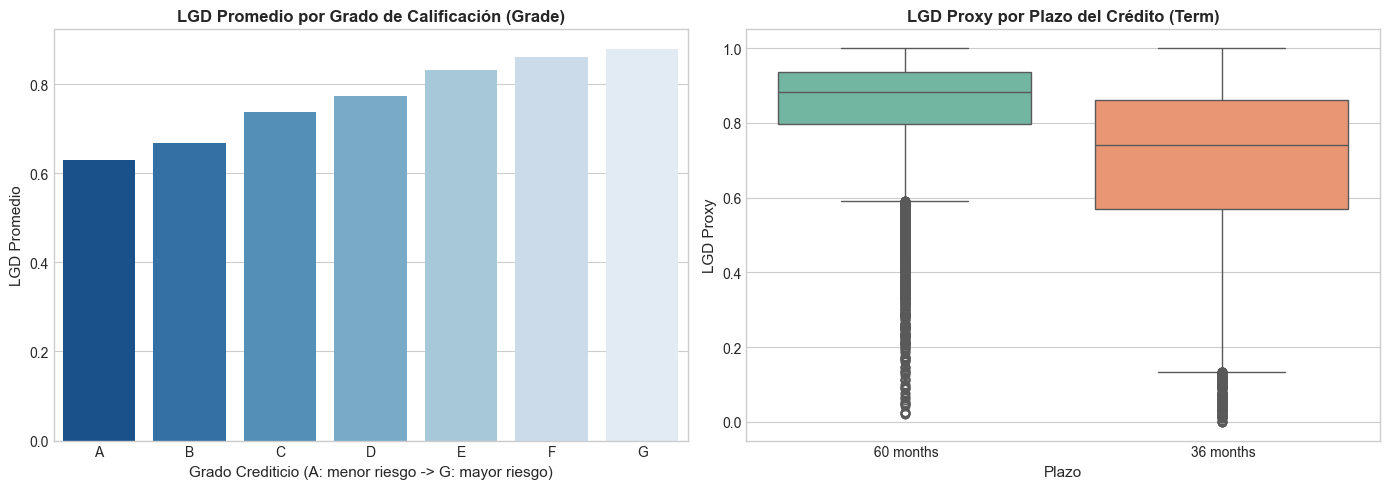

--- LGD POR GRADO CREDITICIO ---


,count,mean,median,std
grade,,,,
A,2664,0.63,0.67,0.23
B,9717,0.67,0.71,0.21
C,13002,0.74,0.79,0.19
D,10798,0.77,0.83,0.19
E,6459,0.83,0.87,0.15
F,3013,0.86,0.90,0.13
G,814,0.88,0.92,0.12


In [17]:
# Cruce de LGD por Grado de Riesgo (Grade)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
order_grades = sorted(df_indicadores['grade'].dropna().unique())
sns.barplot(data=df_indicadores, x='grade', y='LGD_proxy_clip', order=order_grades, palette='Blues_r', errorbar=None)
plt.title('LGD Promedio por Grado de Calificación (Grade)', fontweight='bold')
plt.xlabel('Grado Crediticio (A: menor riesgo -> G: mayor riesgo)')
plt.ylabel('LGD Promedio')

plt.subplot(1, 2, 2)
sns.boxplot(data=df_indicadores, x='term', y='LGD_proxy_clip', palette='Set2')
plt.title('LGD Proxy por Plazo del Crédito (Term)', fontweight='bold')
plt.xlabel('Plazo')
plt.ylabel('LGD Proxy')

plt.tight_layout()
plt.show()

# Tabla resumen por Grade
grade_summary = df_indicadores.groupby('grade')['LGD_proxy_clip'].agg(['count', 'mean', 'median', 'std'])
print("--- LGD POR GRADO CREDITICIO ---")
display(grade_summary)

### Contraste Estadístico de Hipótesis: ANOVA y Prueba Post-Hoc de Tukey HSD

Evaluamos si las diferencias en la severidad media de LGD entre los 7 grados (`grade`: A hasta G) son estadísticamente significativas (alfa = 0.05) y definimos los grupos homogéneos resultantes para el modelamiento predictivo.

ANOVA One-Way: F = 953.7735, p-value = 0.0000e+00

--- RESULTADOS DE LA PRUEBA DE TUKEY HSD (COMPARACIONES MULTIPLES) ---
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower  upper  reject
--------------------------------------------------
     A      B   0.0387    0.0 0.0266 0.0509   True
     A      C   0.1077    0.0 0.0959 0.1196   True
     A      D    0.144    0.0  0.132 0.1561   True
     A      E   0.2022    0.0 0.1894  0.215   True
     A      F   0.2296    0.0 0.2148 0.2444   True
     A      G   0.2486    0.0 0.2263 0.2709   True
     B      C    0.069    0.0 0.0615 0.0764   True
     B      D   0.1053    0.0 0.0975  0.113   True
     B      E   0.1635    0.0 0.1545 0.1724   True
     B      F   0.1909    0.0 0.1793 0.2025   True
     B      G   0.2099    0.0 0.1896 0.2302   True
     C      D   0.0363    0.0  0.029 0.0435   True
     C      E   0.0945    0.0  0.086  0.103   True
     C      F   0.1219    0.0 0.1106 0.1331   True
     C    

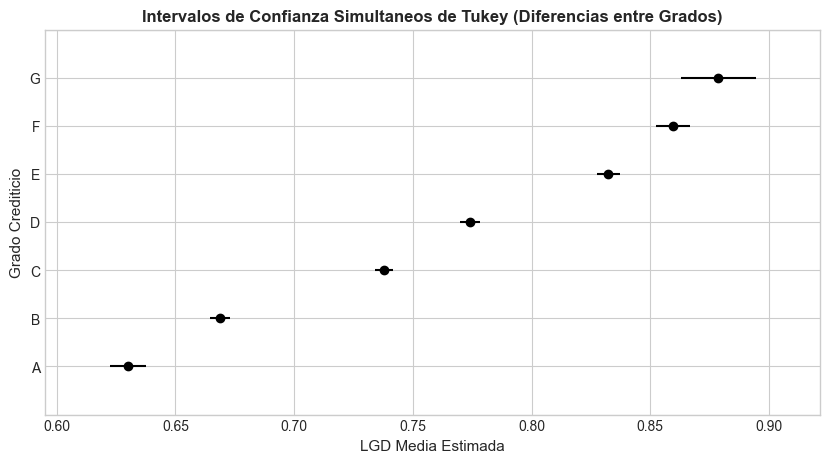


CONCLUSION DE GRUPOS HOMOGENEOS:
1. Existen 6 grupos estadisticamente diferenciados: A, B, C, D, E y [F, G].
2. La comparacion entre F y G arrojo p-adj = 0.1424 (no significativa); por ende, en el modelo de regresion se fusionaran en un solo grupo: F_G.


In [18]:
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# 1. ANOVA One-Way
grados_series = [group["LGD_proxy_clip"].values for name, group in df_indicadores.groupby("grade")]
f_stat, p_val = stats.f_oneway(*grados_series)
print(f"ANOVA One-Way: F = {f_stat:.4f}, p-value = {p_val:.4e}")

# 2. Prueba de Tukey HSD
tukey_res = pairwise_tukeyhsd(endog=df_indicadores["LGD_proxy_clip"], groups=df_indicadores["grade"], alpha=0.05)
print("\n--- RESULTADOS DE LA PRUEBA DE TUKEY HSD (COMPARACIONES MULTIPLES) ---")
print(tukey_res.summary())

# 3. Grafico de Intervalos de Confianza de Tukey
fig = tukey_res.plot_simultaneous(figsize=(10, 5))
plt.title("Intervalos de Confianza Simultaneos de Tukey (Diferencias entre Grados)", fontweight="bold")
plt.xlabel("LGD Media Estimada")
plt.ylabel("Grado Crediticio")
plt.show()

print("\nCONCLUSION DE GRUPOS HOMOGENEOS:")
print("1. Existen 6 grupos estadisticamente diferenciados: A, B, C, D, E y [F, G].")
print("2. La comparacion entre F y G arrojo p-adj = 0.1424 (no significativa); por ende, en el modelo de regresion se fusionaran en un solo grupo: F_G.")

--- 
## Etapa 8. Limitaciones e Interpretación Metodológica

De acuerdo con los resultados observados, se documentan las siguientes limitaciones analíticas esenciales para el proyecto:

1. **Monto Original vs EAD:** `funded_amnt` representa el valor inicial financiado y sirve como base aproximada, pero no refleja la evolución exacta del saldo vivo en el instante exacto en que ocurrió el primer impago.
2. **Naturaleza Acumulativa de `total_rec_prncp`:** Esta variable consolida amortizaciones normales previas al default y cualquier aporte de capital durante la cobranza, sin desglosar la cronología mensual.
3. **Heterogeneidad temporal de `recoveries`:** Los créditos castigados recientemente tienen procesos de cobranza aún activos, por lo que su severidad observada puede ser mayor que la de créditos con años de gestión de cobranza.
4. **Bimodalidad y Acotamiento:** La distribución de LGD se concentra fuertemente cerca de 1.0 (pérdida casi total) y valores intermedios, lo que implica que modelos lineales simples (OLS estándar) podrían requerir técnicas especiales para respetar el rango $[0, 1]$.